In [1]:
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import torch
from torch import optim
import os

In [2]:
# import requests
# import zipfile
# import os

# url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

# zip_path = "./eurosat.zip"
# extract_path = "./eurosat"

# response = requests.get(url, stream=True)
# response.raise_for_status()

# with open(zip_path, "wb") as f:
#     for chunk in response.iter_content(chunk_size=8192):
#         if chunk:
#             f.write(chunk)

# os.makedirs(extract_path, exist_ok=True)

# with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#     zip_ref.extractall(extract_path)
# print(f"Extracted dataset to {extract_path}")

In [2]:
def get_train_test_loader(root, test_size, split_random_state, batch_size, stratify=True):

    eurosat_dataset = ImageFolder(
        root=root,
        transform=ToTensor() # performs the scaling i.e. divide by 255
    )

    labels = eurosat_dataset.targets

    indices = list(range(len(eurosat_dataset)))

    if stratify:
        train_indices, test_indices = train_test_split(indices, test_size=test_size, random_state=split_random_state, stratify=labels)
    else:
        train_indices, test_indices = train_test_split(indices, test_size=test_size, random_state=split_random_state)

    train_dataset = Subset(eurosat_dataset, train_indices)
    test_dataset = Subset(eurosat_dataset, test_indices)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=True
    )

    return train_loader, test_loader


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [5]:
class CNN(nn.Module):

    def __init__(self, input_features): # Input features => chanels
        # Input image shape => 3 x 64 x 64
        # Max pool reduces height and width
        # Kernel adjusts in first dim

        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_features, 32, kernel_size=3, padding="same"), # input_features or input dimension 1x28x28(1 channel), 32 kernels, kernel size, pad
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 32 x 32 x 32

            nn.Conv2d(32, 64, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 64 x 16 X 16

            nn.Conv2d(64, 128, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 128 x 8 x 8
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(128, 10)
        )

    def forward(self, X):
        x = self.features(X)
        x = self.classifier(x)

        return x

In [6]:
from torchvision.io.image import read_image

read_image("eurosat/Forest/Forest_1.jpg").shape

torch.Size([3, 64, 64])

In [4]:
def calc_batch_loss(model, input_batch, target_batch, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [5]:
def calc_loss_loader(dataloader, model, device, num_batches):
    total_loss = 0
    if len(dataloader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(dataloader)
    else:

        num_batches = min(num_batches, len(dataloader))

    for i, (input_batch, target_batch) in enumerate(dataloader):
        if i < num_batches:
            loss = calc_batch_loss(model, input_batch, target_batch, device)
            total_loss += loss.item()
        else:
            break

    return total_loss / num_batches

    

In [6]:
def evaluate_model(model, train_loader, val_loader, device):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=50)

    model.train()
    return train_loss, val_loss

In [11]:
class EarlyStopping:
    def __init__(self, patience: int = 1, min_delta: int = 0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_validation_loss = float('inf')

    def early_stop(self, validation_loss, model, step):

        if validation_loss < self.min_validation_loss:
            self.min_validation_loss = validation_loss
            self.counter = 0
            print(f"Saving model in {step} with val loss: {self.min_validation_loss}")
            torch.save(model.state_dict(), f"model.pt")
            
        elif validation_loss > (self.min_validation_loss + self.min_delta):
            self.counter += 1
            if self.counter >= self.patience:
                return True

        return False

In [11]:
def train_cnn_model(model, train_loader, val_loader, epochs, optimizer, patience) -> dict[list, list]:

    global_step = 0
    stop_training = False

    train_losses, val_losses = [], []

    early_stopper = EarlyStopping(patience=patience, min_delta=0.03)

    for epoch in range(epochs):

        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_batch_loss(model, input_batch, target_batch, device)
            loss.backward()
            optimizer.step()
            global_step += 1

            if global_step % 100 == 0:
                train_loss, val_loss = evaluate_model(model, train_loader, val_loader, device)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Epoch: {epoch + 1} (step {global_step:06d}): "
                      f"Train loss: {train_loss}, val_loss: {val_loss}")
                
                if early_stopper.early_stop(val_loss, model, global_step):
                    print(f"Early stopping stopped the training at val loss: {val_loss}, in step: {global_step}")
                    stop_training = True
                    break

        if stop_training:
            break

    return {"Train loss": train_losses, "Val loss": val_losses }

In [12]:
LR = 0.001

model = CNN(3)

model = model.to(device)

# loss_func = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

In [13]:
from torchinfo import summary

summary(model, input_size=(32, 3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 10]                  --
├─Sequential: 1-1                        [32, 128, 8, 8]           --
│    └─Conv2d: 2-1                       [32, 32, 64, 64]          896
│    └─ReLU: 2-2                         [32, 32, 64, 64]          --
│    └─MaxPool2d: 2-3                    [32, 32, 32, 32]          --
│    └─Conv2d: 2-4                       [32, 64, 32, 32]          18,496
│    └─ReLU: 2-5                         [32, 64, 32, 32]          --
│    └─MaxPool2d: 2-6                    [32, 64, 16, 16]          --
│    └─Conv2d: 2-7                       [32, 128, 16, 16]         73,856
│    └─ReLU: 2-8                         [32, 128, 16, 16]         --
│    └─MaxPool2d: 2-9                    [32, 128, 8, 8]           --
├─Sequential: 1-2                        [32, 10]                  --
│    └─Flatten: 2-10                     [32, 8192]                --
│    └

In [14]:
train_loader, test_loader = get_train_test_loader("eurosat", 0.2, 42, 32, True)

In [17]:
history = train_cnn_model(model=model, 
                train_loader=train_loader, 
                val_loader=test_loader,
                epochs=10,
                optimizer=optimizer,
                patience=7)

Epoch: 1 (step 000100): Train loss: 1.5404565572738647, val_loss: 1.5044338583946228
Saving model in 100 with val loss: 1.5044338583946228
Epoch: 1 (step 000200): Train loss: 1.2956558227539063, val_loss: 1.2013088619709016
Saving model in 200 with val loss: 1.2013088619709016
Epoch: 1 (step 000300): Train loss: 1.048155927658081, val_loss: 1.0081927680969238
Saving model in 300 with val loss: 1.0081927680969238
Epoch: 1 (step 000400): Train loss: 0.8182925224304199, val_loss: 0.9714807569980621
Saving model in 400 with val loss: 0.9714807569980621
Epoch: 1 (step 000500): Train loss: 0.755596125125885, val_loss: 0.8474632060527801
Saving model in 500 with val loss: 0.8474632060527801
Epoch: 1 (step 000600): Train loss: 0.8928669095039368, val_loss: 0.889021133184433
Epoch: 1 (step 000700): Train loss: 1.1144005060195923, val_loss: 0.9878523135185242
Epoch: 2 (step 000800): Train loss: 0.7090909004211425, val_loss: 0.7661498367786408
Saving model in 800 with val loss: 0.7661498367786408

In [18]:
len(train_loader)

750

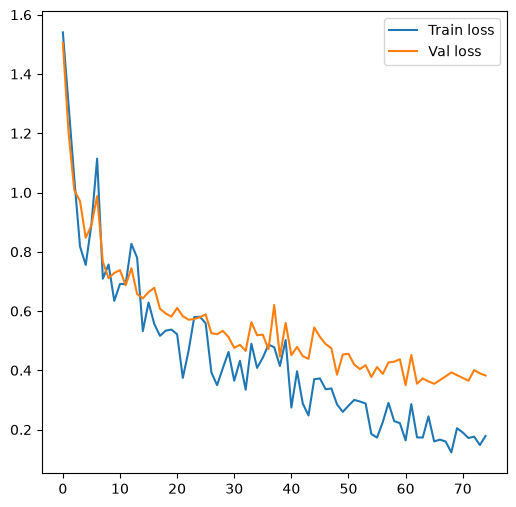

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.plot(history["Train loss"], label="Train loss")
plt.plot(history["Val loss"], label="Val loss")
plt.legend()
plt.show()

In [8]:
from tqdm import tqdm

def check_accuracy_loss(model, test_loader, device) -> tuple[float, float]:

    total_loss = 0.0
    correct = 0
    total = 0

    model.eval()
    with torch.no_grad():

        for input_batch, labels in tqdm(test_loader, desc="Evaluating model..."):
            input_batch = input_batch.to(device)
            labels = labels.to(device)

            logits = model(input_batch)

            loss = torch.nn.functional.cross_entropy(logits, labels)

            batch_size = labels.shape[0]

            total_loss += loss.item() * batch_size #Multiply each loss by its batch size. This converts each batch's average loss into its total loss

            _, predictions = torch.max(logits, 1)

            total = total + batch_size

            correct += (predictions == labels).sum().item()

    avg_loss = total_loss / total
    avg_accuracy = correct / total

    return avg_loss, avg_accuracy

In [23]:
model = CNN(3)

model.load_state_dict(
    torch.load("model.pt", map_location=device)
)

model.to(device)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [24]:
test_loss, test_accuracy = check_accuracy_loss(model, test_loader, device)

Evaluating model...: 100%|██████████| 188/188 [00:05<00:00, 32.34it/s]


In [25]:
test_loss

0.35711872231960295

In [26]:
test_accuracy

0.874

In [27]:
for x, y in test_loader:
    print(x, y)
    break

tensor([[[[0.6118, 0.5843, 0.4353,  ..., 0.5529, 0.3922, 0.2353],
          [0.5922, 0.5725, 0.4314,  ..., 0.5373, 0.3804, 0.2314],
          [0.4431, 0.4353, 0.4078,  ..., 0.4000, 0.2745, 0.2039],
          ...,
          [0.4549, 0.4627, 0.5843,  ..., 0.4902, 0.3725, 0.5020],
          [0.4510, 0.4471, 0.5569,  ..., 0.5804, 0.5098, 0.6275],
          [0.6784, 0.6784, 0.4863,  ..., 0.6549, 0.5922, 0.6078]],

         [[0.5176, 0.5255, 0.4275,  ..., 0.5098, 0.4039, 0.2824],
          [0.5216, 0.5255, 0.4275,  ..., 0.5137, 0.4078, 0.2863],
          [0.4235, 0.4275, 0.4078,  ..., 0.4314, 0.3294, 0.2824],
          ...,
          [0.4824, 0.4824, 0.5804,  ..., 0.4863, 0.3843, 0.5216],
          [0.4706, 0.4667, 0.5569,  ..., 0.5725, 0.5098, 0.6235],
          [0.6980, 0.6980, 0.4863,  ..., 0.6431, 0.5843, 0.6000]],

         [[0.5020, 0.5137, 0.4471,  ..., 0.5020, 0.4392, 0.3294],
          [0.5137, 0.5255, 0.4471,  ..., 0.5137, 0.4471, 0.3294],
          [0.4392, 0.4471, 0.4392,  ..., 0

In [29]:
with torch.no_grad():
    logits = model(x.to(device))
    print(logits)

tensor([[-9.6737e+00, -8.7749e+00, -1.0376e+00,  2.1230e+00,  5.3571e+00,
         -8.5735e+00, -7.8331e-01,  1.7457e-02, -3.7840e+00, -1.3579e+01],
        [ 3.5192e-01, -8.2500e+00, -5.7612e-01,  4.1932e-01, -5.3434e+00,
         -2.0442e+00,  5.1116e+00, -4.3883e+00, -5.4901e+00, -1.1890e+01],
        [-4.7350e+00, -2.4115e+00,  7.0281e+00, -2.9232e+00, -9.3706e+00,
         -4.7137e+00, -1.7265e+00, -9.6795e+00, -3.9737e+00, -5.8505e+00],
        [-5.1575e+00, -3.8718e-01,  7.2261e+00, -5.5319e+00, -1.1258e+01,
          1.5379e-01,  2.2027e+00, -6.6901e+00, -9.4215e+00, -6.9739e+00],
        [-6.0448e-01, -3.9867e+00, -1.6631e+00, -3.0531e+00, -1.3668e+01,
          4.6174e+00, -2.0965e+00, -1.2104e+01, -4.1312e+00, -2.7077e+00],
        [-4.0781e-01,  6.5689e+00, -2.7400e+00, -2.4008e+00, -1.2208e+01,
         -4.2781e+00, -8.8972e+00, -1.0358e+01, -9.9077e-01, -1.7686e+00],
        [-2.5752e+00, -1.1459e+01, -6.7541e+00,  1.3279e+01, -1.1817e+01,
         -1.2826e+01, -7.4264e+0

In [30]:
logits.shape

torch.Size([32, 10])

In [31]:
value, indices = torch.max(logits, 1)
indices

tensor([4, 6, 2, 2, 5, 1, 3, 7, 4, 4, 5, 5, 5, 8, 9, 3, 3, 5, 8, 9, 7, 2, 4, 6,
        5, 6, 8, 7, 9, 2, 1, 1], device='cuda:0')

In [32]:
y

tensor([4, 6, 2, 2, 5, 1, 3, 7, 4, 4, 8, 5, 5, 3, 9, 3, 8, 5, 8, 9, 7, 2, 4, 3,
        5, 6, 8, 7, 9, 2, 1, 1])

## Trying with data augmentation

**Maximum number of images is 3000 and minimum is 2000**
**Performing data augmentation in minority classes** 

In [2]:
classes = os.listdir("eurosat")

for cls in classes:
    print(f"{cls} -> Images count: {len(os.listdir(f'eurosat/{cls}'))}")

AnnualCrop -> Images count: 3000
Forest -> Images count: 3000
HerbaceousVegetation -> Images count: 3000
Highway -> Images count: 2500
Industrial -> Images count: 2500
Pasture -> Images count: 2000
PermanentCrop -> Images count: 2500
Residential -> Images count: 3000
River -> Images count: 2500
SeaLake -> Images count: 3000


In [9]:
import os
import random
from PIL import Image
from tqdm import tqdm
from torchvision.transforms import v2

root = "eurosat"

target_count = 3000

extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

augment = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomRotation(90),
    v2.RandomAutocontrast(p=0.3),
])

random.seed(42)

def augment_images(root, target_count, augment):

    for class_name in tqdm(os.listdir(root), desc="Augmentation"):
        class_dir = os.path.join(root, class_name)

        if not os.path.isdir(class_dir):
            continue

        images = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith(extensions)
            and not f.startswith("aug_")
        ]

        current_count = len(images)

        if current_count >= target_count:
            print(f"{class_name} has already 3000 images")
            continue

        needed = target_count - current_count
        print(f"{class_name}: {current_count} images; generating needed {needed} images.")

        for i in range(needed):
            source_name = random.choice(images)
            source_path = os.path.join(class_dir, source_name)

            with Image.open(source_path) as img:

                img = img.convert("RGB")

                augmented = augment(img)

                output_path = os.path.join(
                    class_dir, f"aug_{i:04d}_{os.path.splitext(source_name)[0]}.jpg"
                )

                augmented.save(output_path, quality=95)

        print(f"{class_name} finished")

    print("Offline augmentation complete!")

In [10]:
augment_images(root, target_count, augment)

Augmentation:   0%|          | 0/10 [00:00<?, ?it/s]

AnnualCrop has already 3000 images
Forest has already 3000 images
HerbaceousVegetation has already 3000 images
Highway: 2500 images; generating needed 500 images.


Augmentation:  40%|████      | 4/10 [00:00<00:01,  5.10it/s]

Highway finished
Industrial: 2500 images; generating needed 500 images.


Augmentation:  50%|█████     | 5/10 [00:01<00:01,  2.79it/s]

...

Pasture finished
PermanentCrop: 2500 images; generating needed 500 images.


Augmentation:  70%|███████   | 7/10 [00:03<00:02,  1.41it/s]

PermanentCrop finished
Residential has already 3000 images
River: 2500 images; generating needed 500 images.


Augmentation: 100%|██████████| 10/10 [00:04<00:00,  2.12it/s]

River finished
SeaLake has already 3000 images
Offline augmentation complete!


In [12]:
for cls in os.listdir(root):
    print(f"len of {cls}: {len(os.listdir(os.path.join(root, cls)))}")

len of AnnualCrop: 3000
len of Forest: 3000
len of HerbaceousVegetation: 3000
len of Highway: 3000
len of Industrial: 3000
len of Pasture: 3000
len of PermanentCrop: 3000
len of Residential: 3000
len of River: 3000
len of SeaLake: 3000


In [49]:
model = CNN(3)

model = model.to(device)

optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

In [50]:
train_loader, test_loader = get_train_test_loader("eurosat", 0.2, 42, 32, True)

In [51]:
history = train_cnn_model(model, train_loader, test_loader, 10, optimizer, patience=7)

Epoch: 1 (step 000100): Train loss: 1.7422285795211792, val_loss: 1.5731410264968873
Saving model in 100 with val loss: 1.5731410264968873
Epoch: 1 (step 000200): Train loss: 1.3350098848342895, val_loss: 1.2237896144390106
Saving model in 200 with val loss: 1.2237896144390106
Epoch: 1 (step 000300): Train loss: 1.0023672580718994, val_loss: 1.06656840801239
Saving model in 300 with val loss: 1.06656840801239
Epoch: 1 (step 000400): Train loss: 1.1896770238876342, val_loss: 1.3194030964374541
Epoch: 1 (step 000500): Train loss: 1.0245418548583984, val_loss: 1.0358431375026702
Saving model in 500 with val loss: 1.0358431375026702
Epoch: 1 (step 000600): Train loss: 0.9133189916610718, val_loss: 0.9050444436073303
Saving model in 600 with val loss: 0.9050444436073303
Epoch: 1 (step 000700): Train loss: 0.6751486778259277, val_loss: 0.7809733891487122
Saving model in 700 with val loss: 0.7809733891487122
Epoch: 2 (step 000800): Train loss: 0.8344450712203979, val_loss: 0.8267594349384307


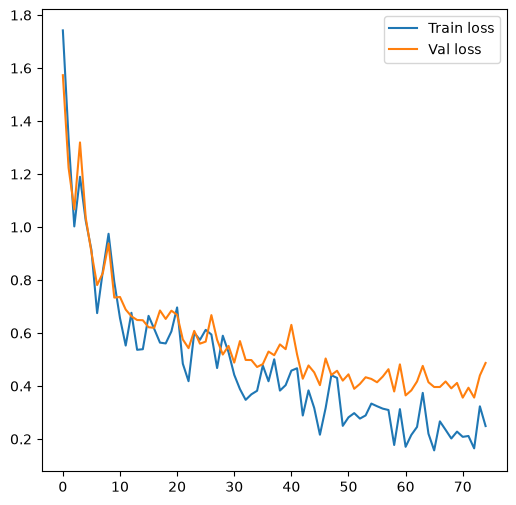

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.plot(history["Train loss"], label="Train loss")
plt.plot(history["Val loss"], label="Val loss")
plt.legend()
plt.show()

In [54]:
model2 = CNN(3)

model2.load_state_dict(
    torch.load("model2.pt", map_location=device)
)

model2.to(device)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [55]:
test_loss, test_accuracy = check_accuracy_loss(model2, test_loader, device)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Evaluating model...: 100%|██████████| 188/188 [00:02<00:00, 63.38it/s]

Test loss: 0.3619051283796628
Test accuracy: 0.8726666666666667


**No Improvement, trying new model with some changes**

In [13]:
def train_cnn_model_v2(model, train_loader, val_loader, epochs, optimizer, patience) -> dict[list, list]:

    global_step = 0
    stop_training = False

    train_losses, val_losses = [], []

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5,
        threshold=0.003,
        threshold_mode="abs",
        cooldown=2,
        min_lr=1e-6
    )

    early_stopper = EarlyStopping(patience=patience, min_delta=0.005)

    for epoch in range(epochs):

        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_batch_loss(model, input_batch, target_batch, device)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            
            optimizer.step()
            global_step += 1


            if global_step % 100 == 0:
                train_loss, val_loss = evaluate_model(model, train_loader, val_loader, device)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                scheduler.step(val_loss)
                print(f"Epoch: {epoch + 1} (step {global_step:06d}): "
                      f"Train loss: {train_loss}, val_loss: {val_loss}")
                
                if early_stopper.early_stop(val_loss, model, global_step):
                    print(f"Early stopping stopped the training at val loss: {val_loss}, in step: {global_step}")
                    stop_training = True
                    break

        if stop_training:
            break

    return {"Train loss": train_losses, "Val loss": val_losses }

In [14]:
class CNNnew(nn.Module):

    def __init__(self, input_features): # Input features => chanels
        # Input image shape => 3 x 64 x 64
        # Max pool reduces height and width
        # Kernel adjusts in first dim

        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_features, 32, kernel_size=3, padding="same", bias=False), # input_features or input dimension 1x28x28(1 channel), 32 kernels, kernel size, pad
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 32 x 32 x 32

            nn.Conv2d(32, 64, kernel_size=3, padding="same", bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 64 x 16 X 16

            nn.Conv2d(64, 128, kernel_size=3, padding="same", bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # image shape => 128 x 8 x 8
        )

        self.gap = nn.AdaptiveAvgPool2d((1,1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(256, 10)
        )

    def forward(self, X):
        x = self.features(X)
        x = self.gap(x)
        x = self.classifier(x)

        return x

In [17]:
new_model = CNNnew(3).to(device)

optimizer = optim.AdamW(new_model.parameters(), lr=0.001, weight_decay=1e-4)

In [20]:
train_loader, test_loader = get_train_test_loader("eurosat", 0.2, 42, 32, True)

In [21]:
history = train_cnn_model_v2(new_model, train_loader, test_loader, 15, optimizer, patience=10)

Epoch: 1 (step 000100): Train loss: 1.2116504907608032, val_loss: 1.2405050218105316
Saving model in 100 with val loss: 1.2405050218105316
Epoch: 1 (step 000200): Train loss: 0.8068766593933105, val_loss: 0.7946448564529419
Saving model in 200 with val loss: 0.7946448564529419
Epoch: 1 (step 000300): Train loss: 0.9388441324234009, val_loss: 1.116870266199112
Epoch: 1 (step 000400): Train loss: 2.8124269008636475, val_loss: 2.9306989192962645
Epoch: 1 (step 000500): Train loss: 0.7787036061286926, val_loss: 0.833394136428833
Epoch: 1 (step 000600): Train loss: 0.8677047610282898, val_loss: 0.790703899860382
Saving model in 600 with val loss: 0.790703899860382
Epoch: 1 (step 000700): Train loss: 1.3042726397514344, val_loss: 1.4341092431545257
Epoch: 2 (step 000800): Train loss: 0.7210089802742005, val_loss: 0.6679887664318085
Saving model in 800 with val loss: 0.6679887664318085
Epoch: 2 (step 000900): Train loss: 0.7775559186935425, val_loss: 0.8281456506252289
Epoch: 2 (step 001000):

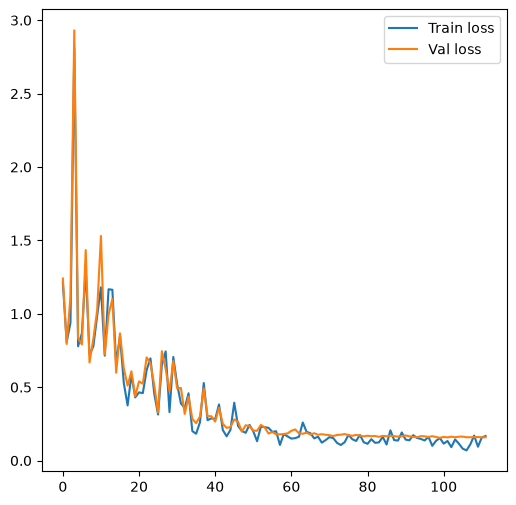

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.plot(history["Train loss"], label="Train loss")
plt.plot(history["Val loss"], label="Val loss")
plt.legend()
plt.show()

In [23]:
new_model_load = CNNnew(3)

new_model_load.load_state_dict(
    torch.load("model.pt", map_location=device)
)

new_model_load = new_model_load.to(device)

In [24]:
test_loss, test_accuracy = check_accuracy_loss(new_model_load, test_loader, device)

print("Test loss", test_loss)
print("Test accuracy", test_accuracy)

Evaluating model...: 100%|██████████| 188/188 [00:05<00:00, 32.11it/s]

Test loss 0.16732543828090032
Test accuracy 0.9431666666666667


** The Model Improved in performance after Introducing changes in model such as adding Batch Normalization, Dropout layer, aprt from changes in model adding Gradient clipping and LRscheduler it helped tthe model to reduce the val loss more and improve the accuracy.**